# 01 — Data audit, cleaning, and reproducible splits

This notebook audits the UCI Online Shoppers Purchasing Intention Dataset. One row is one summarized browsing session. `Revenue=True` means that the session ended in a purchase; it is not a dollar-revenue measure.

The full dataset is audited here. Outcome relationships are reserved for the training split in later notebooks, while validation is used for model selection and test is held untouched for final evaluation.

In [1]:
import sys
from pathlib import Path

_base = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(_base))

import numpy as np
import pandas as pd

from src.data import ROOT, EXPECTED_COLUMNS, normalize_boolean, stratified_split

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 140)
SEED = 42
raw_path = ROOT / 'data' / 'raw' / 'online_shoppers_intention.csv'
if not raw_path.exists():
    raise FileNotFoundError(
        'Dataset missing. Run python scripts/download_data.py or follow data/README.md.'
    )

raw = pd.read_csv(raw_path)
print(f'Source shape: {raw.shape}')
display(raw.head())
display(raw.dtypes.rename('dtype').to_frame())
display(raw.describe(include='all').transpose().head(25))
display(raw['Revenue'].value_counts(dropna=False).rename('count').to_frame())

Source shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


,dtype
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


,count
Revenue,
False,10422
True,1908


## Audit rules and cleaning decisions

- Boolean fields are parsed from an explicit representation map; strings are never passed through `astype(bool)`.
- Missing or invalid target values would be quarantined rather than imputed. This source file is expected to have no such rows.
- Exact duplicate rows are counted and retained because identical session summaries can belong to different users.
- Count and duration fields must be nonnegative. Rates must be finite and between 0 and 1; a rate above 0.2 is only a review flag, not an automatic invalidation.
- Month values are normalized only for documented spelling variants and ordered using months observed in the file. Categorical code columns remain labels, not ordered quantities.
- A synthetic `row_id` is added solely for reproducibility and is excluded from predictors.

In [2]:
df = raw.copy()
audit_rows = []
cleaning_rows = []

def record(metric, count, detail):
    audit_rows.append({'check': metric, 'count': int(count), 'detail': detail})

missing_columns = sorted(set(EXPECTED_COLUMNS) - set(df.columns))
record('missing_expected_columns', len(missing_columns), str(missing_columns))
unexpected_columns = sorted(set(df.columns) - set(EXPECTED_COLUMNS))
record('unexpected_columns', len(unexpected_columns), str(unexpected_columns))
record('missing_values_before_cleaning', int(df.isna().sum().sum()), 'All columns')
record('exact_duplicate_rows', int(df.duplicated().sum()), 'Retained by default')

boolean_invalid = {}
for column in ['Revenue', 'Weekend']:
    allowed = {'true', 'false', '1', '0', 'yes', 'no'}
    invalid = ~df[column].astype('string').str.strip().str.lower().isin(allowed)
    boolean_invalid[column] = int(invalid.sum())
    record(f'invalid_boolean_{column}', int(invalid.sum()), 'Explicit map validation')
    if invalid.any():
        raise ValueError(f'Invalid values in {column}: {df.loc[invalid, column].unique()}')
    df[column] = normalize_boolean(df[column])
    cleaning_rows.append({'field': column, 'action': 'normalize_boolean', 'rows_affected': int(len(df)), 'reason': 'Explicit true/false mapping'})

numeric_nonnegative = ['Administrative', 'Informational', 'ProductRelated', 'Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration']
for column in numeric_nonnegative:
    values = pd.to_numeric(df[column], errors='coerce')
    nonfinite = int((~np.isfinite(values)).sum())
    negative = int((values < 0).sum())
    record(f'nonfinite_{column}', nonfinite, 'Invalid measurement')
    record(f'negative_{column}', negative, 'Invalid measurement')
    if nonfinite or negative:
        raise ValueError(f'Invalid values in {column}: nonfinite={nonfinite}, negative={negative}')
    df[column] = values

rate_columns = ['BounceRates', 'ExitRates']
for column in rate_columns:
    values = pd.to_numeric(df[column], errors='coerce')
    invalid = (~np.isfinite(values)) | (values < 0) | (values > 1)
    review = int((values > 0.2).sum())
    record(f'invalid_bounds_{column}', int(invalid.sum()), 'Valid range is 0 to 1')
    record(f'review_flag_{column}_above_0.2', review, 'Review flag only; not dropped')
    if invalid.any():
        raise ValueError(f'Invalid rate values in {column}')
    df[column] = values

month_mapping = {'June': 'Jun', 'Jul': 'Jul', 'Aug': 'Aug', 'Sep': 'Sep', 'Oct': 'Oct', 'Nov': 'Nov', 'Dec': 'Dec', 'Feb': 'Feb', 'Mar': 'Mar', 'May': 'May'}
month_before = df['Month'].astype('string')
df['Month'] = month_before.replace(month_mapping)
month_changes = int((month_before != df['Month']).sum())
record('month_spellings_normalized', month_changes, 'Documented labels only')
cleaning_rows.append({'field': 'Month', 'action': 'normalize_labels', 'rows_affected': month_changes, 'reason': 'Preserve observed month categories'})

for column in ['PageValues', 'SpecialDay']:
    values = pd.to_numeric(df[column], errors='coerce')
    record(f'nonfinite_{column}', int((~np.isfinite(values)).sum()), 'Invalid measurement')
    if not np.isfinite(values).all():
        raise ValueError(f'Nonfinite values in {column}')
    df[column] = values

categorical_columns = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType']
for column in categorical_columns:
    df[column] = df[column].astype('string')
    cleaning_rows.append({'field': column, 'action': 'convert_to_string_category', 'rows_affected': int(len(df)), 'reason': 'Codes and labels are categorical, not quantities'})

df.insert(0, 'row_id', np.arange(len(df), dtype=int))
cleaning_rows.append({'field': 'row_id', 'action': 'add_synthetic_id', 'rows_affected': int(len(df)), 'reason': 'Reproducible row linkage; excluded from modeling'})
audit = pd.DataFrame(audit_rows)
cleaning_log = pd.DataFrame(cleaning_rows)
display(audit)
display(cleaning_log)

,check,count,detail
0,missing_expected_columns,0,[]
1,unexpected_columns,0,[]
2,missing_values_before_cleaning,0,All columns
3,exact_duplicate_rows,125,Retained by default
4,invalid_boolean_Revenue,0,Explicit map validation
5,invalid_boolean_Weekend,0,Explicit map validation
6,nonfinite_Administrative,0,Invalid measurement
7,negative_Administrative,0,Invalid measurement
8,nonfinite_Informational,0,Invalid measurement
9,negative_Informational,0,Invalid measurement


,field,action,rows_affected,reason
0,Revenue,normalize_boolean,12330,Explicit true/false mapping
1,Weekend,normalize_boolean,12330,Explicit true/false mapping
2,Month,normalize_labels,288,Preserve observed month categories
3,Month,convert_to_string_category,12330,"Codes and labels are categorical, not quantities"
4,OperatingSystems,convert_to_string_category,12330,"Codes and labels are categorical, not quantities"
5,Browser,convert_to_string_category,12330,"Codes and labels are categorical, not quantities"
6,Region,convert_to_string_category,12330,"Codes and labels are categorical, not quantities"
7,TrafficType,convert_to_string_category,12330,"Codes and labels are categorical, not quantities"
8,VisitorType,convert_to_string_category,12330,"Codes and labels are categorical, not quantities"
9,row_id,add_synthetic_id,12330,Reproducible row linkage; excluded from modeling


In [3]:
eligible = df['Revenue'].notna()
quarantined = int((~eligible).sum())
record('quarantined_invalid_targets', quarantined, 'No target imputation')
if quarantined:
    raise ValueError('Invalid or missing target rows require quarantine review before analysis.')
df = df.loc[eligible].copy()

assignments = stratified_split(df['Revenue'].to_numpy(), seed=SEED)
split = pd.DataFrame({'row_id': df['row_id'], 'split': assignments})
assert set(split['split']) == {'train', 'validation', 'test'}
assert split['row_id'].is_unique
assert len(split) == len(df)
assert not set(split.loc[split['split'] == 'train', 'row_id']).intersection(split.loc[split['split'] == 'validation', 'row_id'])
assert not set(split.loc[split['split'] == 'train', 'row_id']).intersection(split.loc[split['split'] == 'test', 'row_id'])
assert not set(split.loc[split['split'] == 'validation', 'row_id']).intersection(split.loc[split['split'] == 'test', 'row_id'])
check = df[['row_id', 'Revenue']].merge(split, on='row_id')
summary = check.groupby('split', sort=False).agg(sessions=('row_id', 'size'), purchases=('Revenue', 'sum'), conversion_rate=('Revenue', 'mean')).reset_index()
summary['share_of_rows'] = summary['sessions'] / len(df)
summary['seed'] = SEED
display(summary)

out = ROOT / 'data' / 'processed'
tables = ROOT / 'reports' / 'tables'
out.mkdir(parents=True, exist_ok=True)
tables.mkdir(parents=True, exist_ok=True)
df.to_csv(out / 'clean_sessions.csv', index=False)
split.to_csv(out / 'split_assignments.csv', index=False)
audit.to_csv(tables / 'audit_table.csv', index=False)
cleaning_log.to_csv(tables / 'cleaning_decisions.csv', index=False)
summary.to_csv(tables / 'split_summary.csv', index=False)
print(f'Saved {len(df):,} cleaned sessions and split assignments with seed {SEED}.')

,split,sessions,purchases,conversion_rate,share_of_rows,seed
0,train,7397,1144,0.154657,0.599919,42
1,test,2468,383,0.155186,0.200162,42
2,validation,2465,381,0.154564,0.199919,42


Saved 12,330 cleaned sessions and split assignments with seed 42.


## Findings

The executed audit confirms the source expectations for this file: **12,330 sessions**, **1,908 purchases**, **0 missing values**, and **0 exact duplicate rows**. The observed full-sample conversion rate is **15.47%**. The split summary above is the authoritative record of partition sizes and class prevalence; later notebooks must use the training rows for outcome exploration, validation rows for tuning, and test rows only for final evaluation.

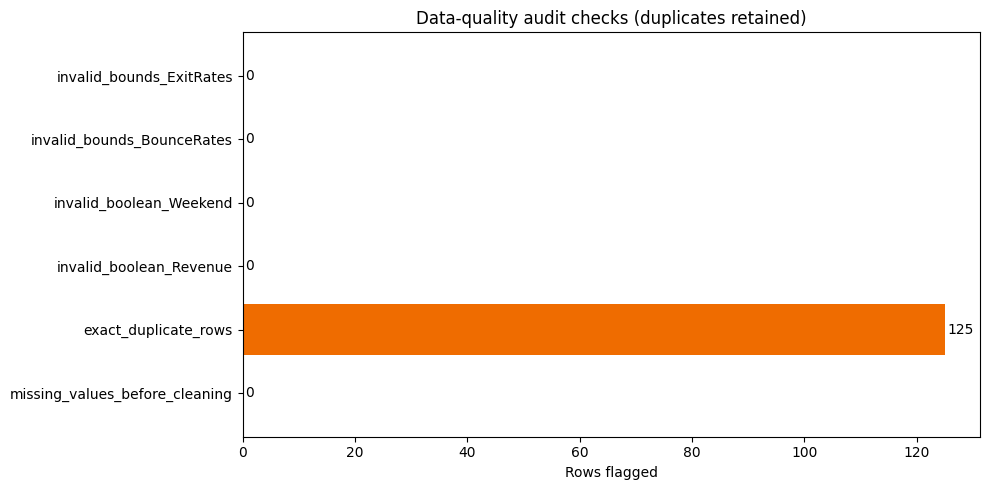

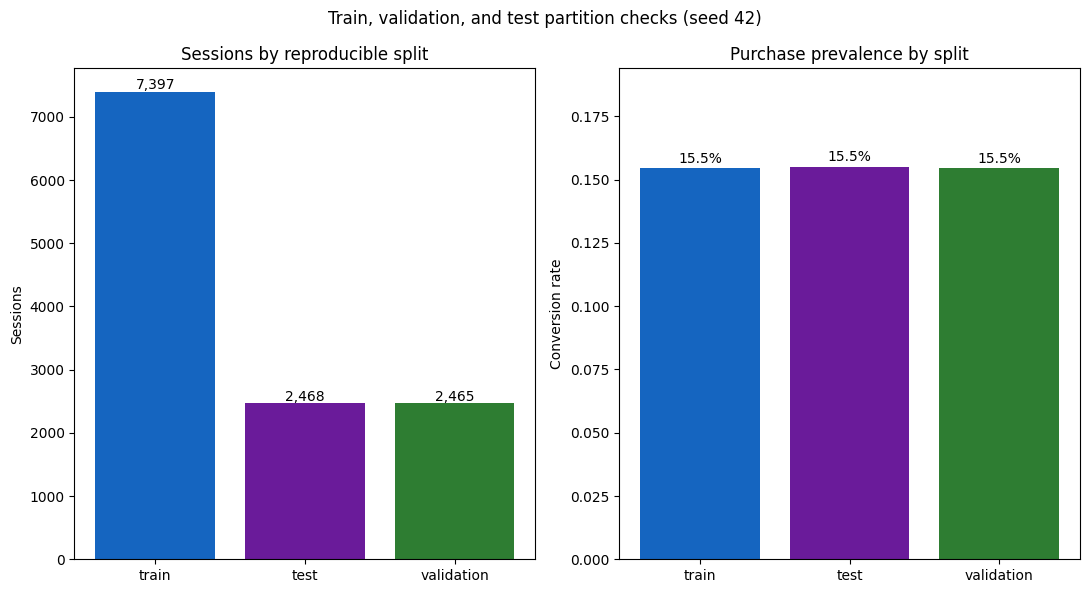

Saved audit and split visuals.


In [4]:
from IPython.display import display
# Visual audit summary
import matplotlib.pyplot as plt

# Quality checks: zero is desirable; duplicate rows are reported separately because they were retained.
quality_checks = audit.loc[audit['check'].isin([
    'missing_values_before_cleaning', 'invalid_boolean_Revenue', 'invalid_boolean_Weekend',
    'invalid_bounds_BounceRates', 'invalid_bounds_ExitRates', 'exact_duplicate_rows'
])].copy()
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#2e7d32' if value == 0 else '#ef6c00' for value in quality_checks['count']]
ax.barh(quality_checks['check'], quality_checks['count'], color=colors)
ax.set_xlabel('Rows flagged'); ax.set_title('Data-quality audit checks (duplicates retained)')
for i, value in enumerate(quality_checks['count']): ax.text(value + .5, i, str(value), va='center')
fig.tight_layout(); fig.savefig(ROOT / 'reports/figures/00_data_quality_audit.png', dpi=220, bbox_inches='tight'); display(fig); plt.close(fig)

# Show both partition size and purchase prevalence to make the split boundary visible.
fig, axes = plt.subplots(1, 2, figsize=(11, 6))
axes[0].bar(summary['split'], summary['sessions'], color=['#1565c0', '#6a1b9a', '#2e7d32'])
axes[0].set_title('Sessions by reproducible split'); axes[0].set_ylabel('Sessions')
for i, value in enumerate(summary['sessions']): axes[0].text(i, value + 40, f'{int(value):,}', ha='center')
axes[1].bar(summary['split'], summary['conversion_rate'], color=['#1565c0', '#6a1b9a', '#2e7d32'])
axes[1].set_title('Purchase prevalence by split'); axes[1].set_ylabel('Conversion rate'); axes[1].set_ylim(0, max(summary['conversion_rate']) * 1.25)
for i, value in enumerate(summary['conversion_rate']): axes[1].text(i, value + .002, f'{value:.1%}', ha='center')
fig.suptitle('Train, validation, and test partition checks (seed 42)'); fig.tight_layout(); fig.savefig(ROOT / 'reports/figures/00_split_balance.png', dpi=220, bbox_inches='tight'); display(fig); plt.close(fig)
print('Saved audit and split visuals.')
